# 00 · A tese da janela (D17)

Toda análise publicada usa só os **últimos 12 meses** (`analysis_window_months`). A premissa: o jogo
muda — agentes novos, nerfs, reworks, rotação de mapas — e dado antigo distorce o resultado atual.
Este notebook testa a premissa sobre o **histórico inteiro**, a única exceção à janela
(`mart_drift_*`), com duas lentes:

1. **o meta de agentes de cada mapa**: quão longe o meta de um trimestre passado está do atual;
2. **a vantagem de lado de cada mapa**: o lado favorecido muda de trimestre para trimestre?

O histórico vem da coleta própria, desde 2025. O período anterior (que alongaria a série) virá de
um dataset pronto importado à parte — ainda pendente.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pipeline import analyses as A
from pipeline import plots as P
from pipeline.stats import fmt

P.setup()
pd.set_option("display.precision", 3)
con = A.connect()  # dbt/metascope.duckdb, do `make build`
A.window(con)

{'first_match': '2025-10-16', 'last_match': '2026-10-11'}

## 1. Meta de agentes: o passado se afasta do presente

Para cada mapa, a **distância de variação total** entre a distribuição de agentes de cada trimestre
e a do trimestre mais recente com amostra (≥ 40 composições): 0 = mesmo meta, 1 = nenhum agente em
comum. O **piso de ruído** é a distância que apareceria só por amostragem se nada tivesse mudado
(percentil 95 de um bootstrap paramétrico com o tamanho de amostra do trimestre).

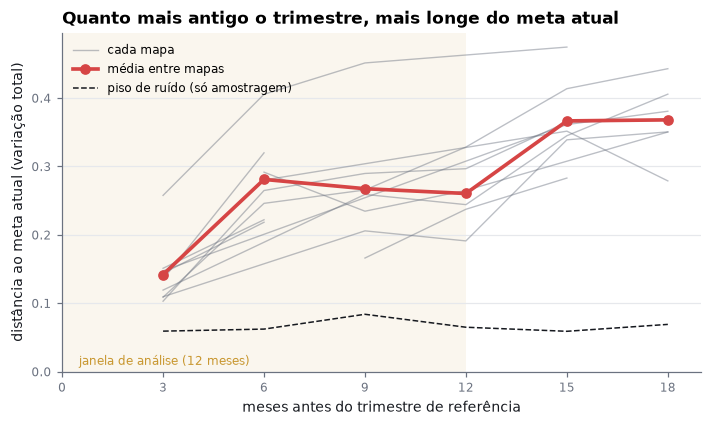

In [2]:
drift_meta = A.meta_drift(con)
by_q, by_age = drift_meta["by_quarter"], drift_meta["by_age"]

fig, ax = plt.subplots(figsize=(7.5, 4))
past = by_q[by_q.quarters_before > 0]
for i, (name, g) in enumerate(past.groupby("map_name")):
    g = g.sort_values("quarters_before")
    ax.plot(g.quarters_before * 3, g.distance, color=P.MUTED, lw=0.9, alpha=0.45,
            label="cada mapa" if i == 0 else None)
ax.plot(by_age.quarters_before * 3, by_age.distance, color=P.ATTACK, lw=2.4, marker="o",
        label="média entre mapas")
ax.plot(by_age.quarters_before * 3, by_age.noise_floor, color=P.INK, lw=1, ls="--",
        label="piso de ruído (só amostragem)")
ax.axvspan(0, 12, color=P.GOLD, alpha=0.08, lw=0)
ax.text(0.5, 0.02, "janela de análise (12 meses)", transform=ax.get_xaxis_transform(),
        fontsize=8, color=P.GOLD)
ax.set_xlim(0, by_age.quarters_before.max() * 3 + 1)
ax.set_xticks(range(0, int(by_age.quarters_before.max()) * 3 + 1, 3))
ax.set_ylim(0, None)
ax.set_xlabel("meses antes do trimestre de referência")
ax.set_ylabel("distância ao meta atual (variação total)")
ax.set_title("Quanto mais antigo o trimestre, mais longe do meta atual")
ax.legend(loc="upper left")
P.save(fig, "drift-meta.png")
plt.show()

In [3]:
(past.pivot_table(index="map_name", columns="quarters_before", values="distance")
     .rename(columns=lambda q: f"-{q * 3} meses").round(2))

quarters_before,-3 meses,-6 meses,-9 meses,-12 meses,-15 meses,-18 meses
map_name,,,,,,
Abyss,NaN,0.29,0.23,0.26,NaN,0.35
Ascent,0.12,NaN,0.26,0.24,0.34,0.41
Bind,0.26,0.41,0.45,NaN,0.47,NaN
Breeze,0.14,0.32,NaN,NaN,NaN,NaN
Corrode,0.14,0.22,NaN,NaN,NaN,NaN
Fracture,0.15,NaN,NaN,NaN,0.36,0.38
Haven,0.10,0.26,0.29,0.30,0.36,0.37
Icebox,0.15,0.22,NaN,NaN,NaN,NaN
Lotus,0.11,NaN,0.21,0.19,0.34,0.35


## 2. Vantagem de lado por trimestre

Rounds regulamentares (1–24) vencidos pelo ataque, por mapa e trimestre, só em mapas com histórico de
lado. Rounds do mesmo mapa são correlacionados: o IC de Wilson usa o **n efetivo** (rounds ÷ efeito
de desenho, estimado por bootstrap de mapas sobre a janela). Os patches maiores (X.00) estão
marcados. Por mapa, um teste de homogeneidade (qui-quadrado sobre o n efetivo, Holm entre mapas)
pergunta se a taxa muda entre trimestres mais do que o acaso explicaria.

efeito de desenho: 1.82


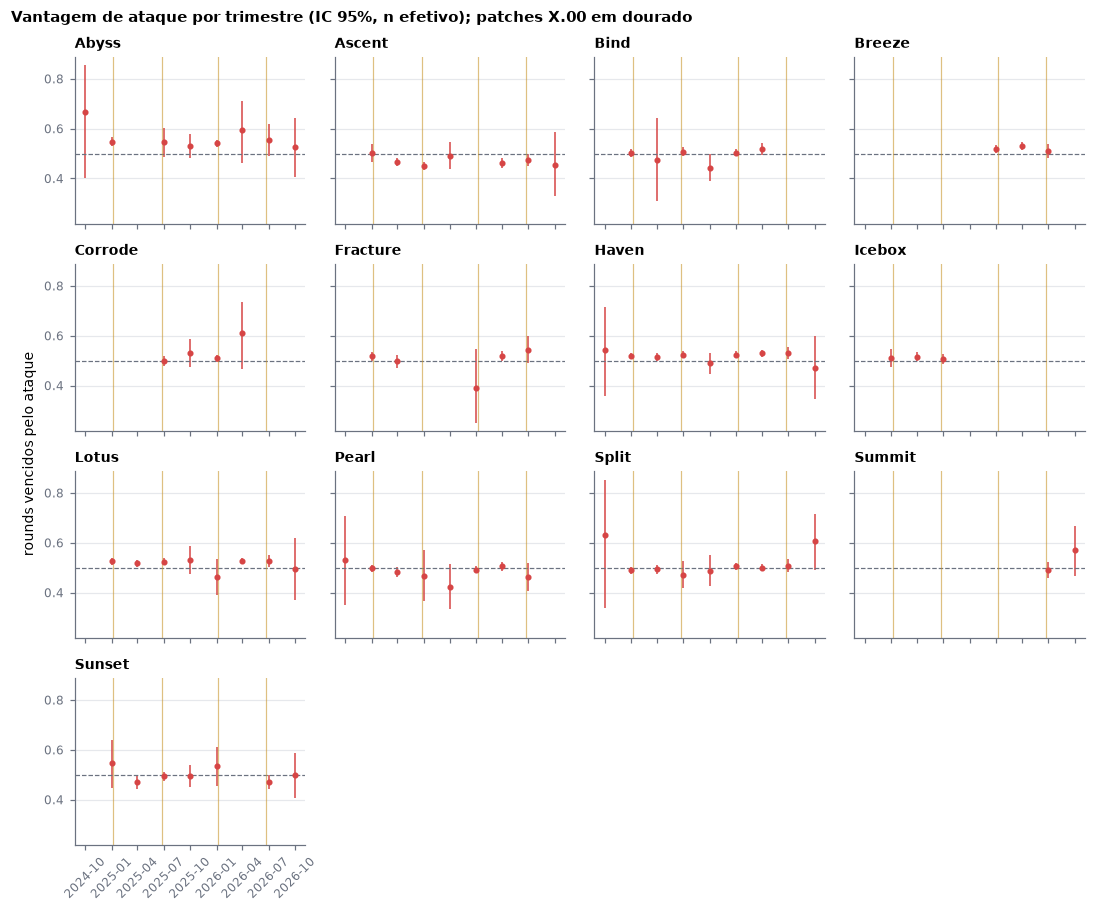

,map_name,quarters,chi2,p,p_adj,changes
0,Abyss,8,2.236,0.946,1.0,False
1,Ascent,7,8.320,0.216,1.0,False
2,Bind,6,6.333,0.275,1.0,False
3,Breeze,3,1.855,0.396,1.0,False
4,Corrode,4,3.531,0.317,1.0,False
5,Fracture,5,5.206,0.267,1.0,False
6,Haven,9,5.904,0.658,1.0,False
7,Icebox,3,0.354,0.838,1.0,False
8,Lotus,8,4.111,0.767,1.0,False
9,Pearl,8,6.882,0.441,1.0,False


In [4]:
drift_side = A.drift(con)
side, homog = drift_side["by_quarter"], drift_side["homogeneity"]
majors = con.sql(
    "select patch, release_date from main_marts.dim_patch "
    "where patch like '%.00' and release_date >= (select min(quarter_start) "
    "from main_analysis.mart_drift_side_by_quarter)"
).df()
print(f"efeito de desenho: {drift_side['design_effect']:.2f}")

maps = sorted(side.map_name.unique())
cols = 4
rows = -(-len(maps) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(10, 2.1 * rows), sharex=True, sharey=True)
for ax, name in zip(axes.flat, maps):
    g = side[side.map_name == name]
    ax.errorbar(g.quarter_start, g.attack_win_rate,
                yerr=[g.attack_win_rate - g.low, g.high - g.attack_win_rate],
                fmt="o", ms=3, color=P.ATTACK, ecolor=P.ATTACK, elinewidth=1, capsize=0)
    ax.axhline(0.5, color=P.MUTED, lw=0.8, ls="--")
    for d in majors.release_date:
        ax.axvline(pd.Timestamp(d), color=P.GOLD, lw=0.8, alpha=0.6)
    ax.set_title(name, fontsize=9)
    ax.tick_params(axis="x", rotation=45)
for ax in axes.flat[len(maps):]:
    ax.set_visible(False)
fig.supylabel("rounds vencidos pelo ataque", fontsize=9)
fig.suptitle("Vantagem de ataque por trimestre (IC 95%, n efetivo); patches X.00 em dourado",
             x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout()
plt.show()
homog.round(3)

## Conclusão

In [5]:
near = by_age[by_age.quarters_before == 1].iloc[0]
far = by_age[by_age.quarters_before >= 4]
changed = int(homog["changes"].sum())
above_floor = (past.low > past.noise_floor).mean()
side_text = (
    f"**{changed} de {len(homog)}** mapas têm vantagem de lado que muda entre trimestres além do "
    "acaso (Holm, α = 0,05)."
    if changed else
    f"**nenhum** dos {len(homog)} mapas tem vantagem de lado que muda entre trimestres além do "
    "acaso (Holm, α = 0,05): com o histórico desde 2025, a deriva de lado é **inconclusiva**. "
    "O efeito de lado é pequeno (poucos pontos percentuais) e a amostra trimestral de cada mapa "
    "não separa mudança de ruído."
)
display(Markdown(f"""
- **Meta:** um trimestre atrás, o meta de um mapa já está a **{fmt(near.distance, 2)}** do atual
  (piso de ruído {fmt(near.noise_floor, 2)}); a 12 meses ou mais, a distância média é
  **{fmt(far.distance.mean(), 2)}**. Em {fmt(above_floor * 100, 0)}% dos pares mapa × trimestre o
  limite inferior do IC fica acima do piso de ruído.
- **Lado:** {side_text}
- **A janela se sustenta pelo meta:** em 12 meses um mapa troca parte grande dos agentes que o
  definem. Dado mais antigo descreve outro jogo; incluí-lo diluiria o resultado atual. O drift de
  lado volta a ser testado quando o histórico anterior a 2025 for importado.
"""))


- **Meta:** um trimestre atrás, o meta de um mapa já está a **0,14** do atual
  (piso de ruído 0,06); a 12 meses ou mais, a distância média é
  **0,33**. Em 100% dos pares mapa × trimestre o
  limite inferior do IC fica acima do piso de ruído.
- **Lado:** **nenhum** dos 13 mapas tem vantagem de lado que muda entre trimestres além do acaso (Holm, α = 0,05): com o histórico desde 2025, a deriva de lado é **inconclusiva**. O efeito de lado é pequeno (poucos pontos percentuais) e a amostra trimestral de cada mapa não separa mudança de ruído.
- **A janela se sustenta pelo meta:** em 12 meses um mapa troca parte grande dos agentes que o
  definem. Dado mais antigo descreve outro jogo; incluí-lo diluiria o resultado atual. O drift de
  lado volta a ser testado quando o histórico anterior a 2025 for importado.
